# <span style="color: #a855f7">Neural network regularization</span>

<span style="color: #a855f7">регресія на load_diabetes, порівняння MLP без регуляризації, з L2, MAE і R² на test, ціль - кількісна оцінка прогресування діабету через рік, не ймовірність захворювання, дані входять до scikit-learn</span>

In [1]:
from copy import deepcopy
from html import escape
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import HTML, display
from sklearn.datasets import load_diabetes
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils import Bunch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

RANDOM_STATE = 42
TEST_SIZE = 0.2
EPOCHS = 50
LEARNING_RATE = 0.001
BATCH_SIZE = 32
L2_WEIGHT_DECAY = 1e-4
OUTPUT_PATH = Path("diabetes_healthrisk_analysis.png")
COLORS = ["#a855f7", "#f472b6", "#60a5fa"]

torch.manual_seed(RANDOM_STATE)
torch.set_num_threads(1)


def colorize(value, *, index=True):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        table = value.to_frame() if isinstance(value, pd.Series) else value
        html = table.to_html(border=0, index=index).replace(
            '<table ', '<table style="color: #a855f7; margin-left: 0; margin-right: auto; border-collapse: collapse" '
        )
        for tag in ("th", "td"):
            html = html.replace(
                f"<{tag}>",
                f'<{tag} style="padding: 6px 12px; border-bottom: 1px solid #746a80">',
            )
        display(HTML(html))
    else:
        display(HTML(f'<p style="color: #a855f7; margin: 12px 0 6px">{escape(str(value))}</p>'))


plt.style.use("dark_background")
plt.rcParams.update({
    "figure.figsize": (10, 5),
    "figure.dpi": 110,
    "figure.facecolor": "#111116",
    "axes.facecolor": "#111116",
    "axes.edgecolor": "#746a80",
    "axes.labelcolor": "#e9d5ff",
    "axes.titlecolor": "#e9d5ff",
    "axes.titlesize": 13,
    "text.color": "#e9d5ff",
    "xtick.color": "#d8c8ed",
    "ytick.color": "#d8c8ed",
    "grid.color": "#746a80",
    "grid.alpha": 0.25,
    "font.size": 10,
})

## <span style="color: #a855f7">Diabetes data and train/test split</span>

<span style="color: #a855f7">442 спостереження, 10 числових ознак, scaled=False повертає вихідну шкалу ознак, split 80/20 з random_state=42 виконується до масштабування, StandardScaler.fit_transform лише для X_train, для X_test - transform, target не масштабується, всі 10 ознак залишаються в моделі</span>

In [2]:
data = load_diabetes(as_frame=True, scaled=False)
if not isinstance(data, Bunch) or not isinstance(data.frame, pd.DataFrame):
    raise TypeError("Expected a Diabetes dataset with a pandas DataFrame")
features = [str(name) for name in data.feature_names]
X = data.frame[features].copy()
y = data.frame["target"].copy()
if not np.isfinite(X.to_numpy(dtype=float)).all() or not np.isfinite(y.to_numpy(dtype=float)).all():
    raise ValueError("Features and target must contain only finite numeric values")
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE,
)
scaler = StandardScaler()
X_train_scaled = np.asarray(scaler.fit_transform(X_train), dtype=np.float32)
X_test_scaled = np.asarray(scaler.transform(X_test), dtype=np.float32)
X_train_tensor = torch.from_numpy(X_train_scaled)
X_test_tensor = torch.from_numpy(X_test_scaled)
y_train_tensor = torch.tensor(y_train.to_numpy(), dtype=torch.float32).reshape(-1, 1)
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)

colorize("First 5 rows: features and target")
colorize(data.frame.head().round(4))
colorize(pd.DataFrame({
    "split": ["train", "test"],
    "X before scaling": [str(X_train.shape), str(X_test.shape)],
    "X after scaling": [str(X_train_scaled.shape), str(X_test_scaled.shape)],
    "y shape": [str(y_train.shape), str(y_test.shape)],
}), index=False)
colorize("Training feature statistics after scaling")
colorize(pd.DataFrame({
    "feature": features,
    "mean": X_train_scaled.astype(float).mean(axis=0),
    "std (ddof=0)": X_train_scaled.astype(float).std(axis=0),
}).round(6), index=False)

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,59.0,2.0,32.1,101.0,157.0,93.2,38.0,4.0,4.8598,87.0,151.0
1,48.0,1.0,21.6,87.0,183.0,103.2,70.0,3.0,3.8918,69.0,75.0
2,72.0,2.0,30.5,93.0,156.0,93.6,41.0,4.0,4.6728,85.0,141.0
3,24.0,1.0,25.3,84.0,198.0,131.4,40.0,5.0,4.8903,89.0,206.0
4,50.0,1.0,23.0,101.0,192.0,125.4,52.0,4.0,4.2905,80.0,135.0


split,X before scaling,X after scaling,y shape
train,"(353, 10)","(353, 10)","(353,)"
test,"(89, 10)","(89, 10)","(89,)"


feature,mean,std (ddof=0)
age,-0.0,1.0
sex,0.0,1.0
bmi,-0.0,1.0
bp,-0.0,1.0
s1,0.0,1.0
s2,0.0,1.0
s3,-0.0,1.0
s4,-0.0,1.0
s5,-0.0,1.0
s6,-0.0,1.0


## <span style="color: #a855f7">MLP architecture and training</span>

<span style="color: #a855f7">архітектура 10 → 64 → 32 → 16 → 1, ReLU після кожного прихованого шару, вихід без активації, MSELoss і Adam з lr=0.001, 50 епох, batch_size=32, останній неповний батч не відкидається, CPU достатньо для цього набору, одна епоха проходить всі 353 train-зразки</span>

In [3]:
initial_model = nn.Sequential(
    nn.Linear(X_train_tensor.shape[1], 64),
    nn.ReLU(),
    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Linear(32, 16),
    nn.ReLU(),
    nn.Linear(16, 1),
)


def train_model(initial_model, dataset, *, weight_decay):
    model = deepcopy(initial_model)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=weight_decay)
    criterion = nn.MSELoss()
    loader = DataLoader(
        dataset, batch_size=BATCH_SIZE, shuffle=True,
        generator=torch.Generator().manual_seed(RANDOM_STATE),
    )
    inputs, targets = dataset.tensors
    model.eval()
    with torch.no_grad():
        history = [criterion(model(inputs), targets).item()]
    for _ in range(EPOCHS):
        model.train()
        for batch_inputs, batch_targets in loader:
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(batch_inputs), batch_targets)
            if not torch.isfinite(loss):
                raise FloatingPointError("Training loss is not finite")
            loss.backward()
            optimizer.step()
        model.eval()
        with torch.no_grad():
            history.append(criterion(model(inputs), targets).item())
    return model, history


colorize(pd.DataFrame({
    "layer": ["Hidden 1", "Hidden 2", "Hidden 3", "Output"],
    "input features": [layer.in_features for layer in initial_model if isinstance(layer, nn.Linear)],
    "neurons": [layer.out_features for layer in initial_model if isinstance(layer, nn.Linear)],
    "activation": ["ReLU", "ReLU", "ReLU", "None"],
}), index=False)
colorize(f"Trainable parameters: {sum(parameter.numel() for parameter in initial_model.parameters())}")

layer,input features,neurons,activation
Hidden 1,10,64,ReLU
Hidden 2,64,32,ReLU
Hidden 3,32,16,ReLU
Output,16,1,None


## <span style="color: #a855f7">Unregularized and L2 experiments</span>

<span style="color: #a855f7">дві незалежні копії початкової моделі, однакові ваги, дані, батчі й 50 епох, відрізняється тільки weight_decay: 0 або 1e-4, використовується Adam за ТЗ, не AdamW, train MSE нижче обчислюється після кожної епохи на всьому train без додавання штрафу L2, test не використовується під час навчання</span>

In [4]:
configurations = {"No regularization": 0.0, "L2 regularization": L2_WEIGHT_DECAY}
models = {}
loss_histories = {}
for name, weight_decay in configurations.items():
    model, history = train_model(initial_model, train_dataset, weight_decay=weight_decay)
    models[name] = model
    loss_histories[name] = history

progress_epochs = [0, *range(10, EPOCHS, 10), EPOCHS]
colorize(pd.DataFrame({
    "epoch": progress_epochs,
    **{name + " train MSE": [history[epoch] for epoch in progress_epochs]
       for name, history in loss_histories.items()},
}).round(4), index=False)

epoch,No regularization train MSE,L2 regularization train MSE
0,29645.9121,29645.9121
10,19637.1152,19579.9453
20,4034.6643,4074.9426
30,3407.6877,3432.5605
40,3153.0623,3170.0110
50,3004.1763,3016.0259


## <span style="color: #a855f7">Test metrics</span>

<span style="color: #a855f7">model.eval і torch.no_grad для передбачень, MAE - середня абсолютна помилка у вихідній шкалі target, менше краще, R² порівнює модель з передбаченням середнього test target, більше краще, від'ємний R² можливий, метрики не є accuracy класифікації</span>

In [5]:
predictions = {}
metrics: dict[str, dict[str, float]] = {}
for name, model in models.items():
    model.eval()
    with torch.no_grad():
        y_pred = model(X_test_tensor).squeeze(1).numpy()
    if y_pred.shape != y_test.shape or not np.isfinite(y_pred).all():
        raise ValueError("Predictions must match the target shape and contain finite values")
    predictions[name] = y_pred
    metrics[name] = {
        "MAE": float(mean_absolute_error(y_test, y_pred)),
        "R²": float(r2_score(y_test, y_pred)),
    }
results = pd.DataFrame.from_dict(metrics, orient="index").rename_axis("configuration")
colorize(results.round(4))
mae_change = metrics["L2 regularization"]["MAE"] - metrics["No regularization"]["MAE"]
r2_change = metrics["L2 regularization"]["R²"] - metrics["No regularization"]["R²"]
colorize(pd.DataFrame({
    "comparison": ["L2 minus no regularization"],
    "MAE change": [mae_change],
    "R² change": [r2_change],
}).round(6), index=False)

,MAE,R²
configuration,,
No regularization,45.4331,0.3929
L2 regularization,45.5439,0.3899


comparison,MAE change,R² change
L2 minus no regularization,0.110764,-0.003009


## <span style="color: #a855f7">Actual vs predicted</span>

<span style="color: #a855f7">один рисунок з двома панелями для обох конфігурацій, по X - реальний y_test, по Y - передбачення, пунктирна діагональ y=x означає ідеальні передбачення, однакові межі та масштаб осей роблять порівняння коректним, зображення зберігається як diabetes_healthrisk_analysis.png</span>

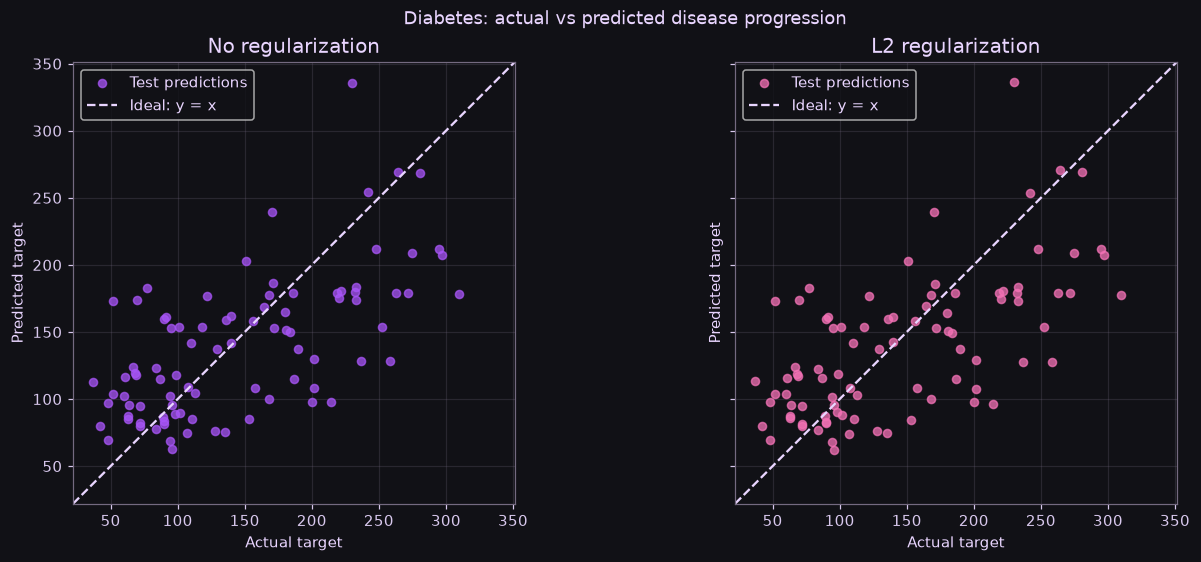

In [6]:
all_values = np.concatenate([y_test.to_numpy(), *predictions.values()])
padding = float(np.ptp(all_values)) * 0.05
limits = (float(all_values.min()) - padding, float(all_values.max()) + padding)
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True, layout="constrained")
for ax, (name, y_pred), color in zip(axes, predictions.items(), COLORS[:2], strict=True):
    ax.scatter(y_test.to_numpy(), y_pred, color=color, alpha=0.75, s=28, label="Test predictions")
    ax.plot(limits, limits, color="#e9d5ff", linestyle="--", label="Ideal: y = x")
    ax.set(title=name, xlabel="Actual target", ylabel="Predicted target", xlim=limits, ylim=limits)
    ax.set_aspect("equal", adjustable="box")
    ax.grid(True)
    ax.set_axisbelow(True)
    ax.legend(loc="upper left")
fig.suptitle("Diabetes: actual vs predicted disease progression")
fig.savefig(OUTPUT_PATH, dpi=160, facecolor=fig.get_facecolor())
plt.show()
colorize(f"Saved plot: {OUTPUT_PATH.name}")

<span style="color: #a855f7">додаткове порівняння: нижче показано різницю передбачень L2 − без регуляризації для кожного test-зразка, нуль означає однаковий прогноз, вище нуля L2 прогнозує більше, нижче - менше, окрема шкала робить невеликі зміни видимими, сама по собі зміна прогнозу не означає покращення точності, це визначають MAE і R² вище</span>

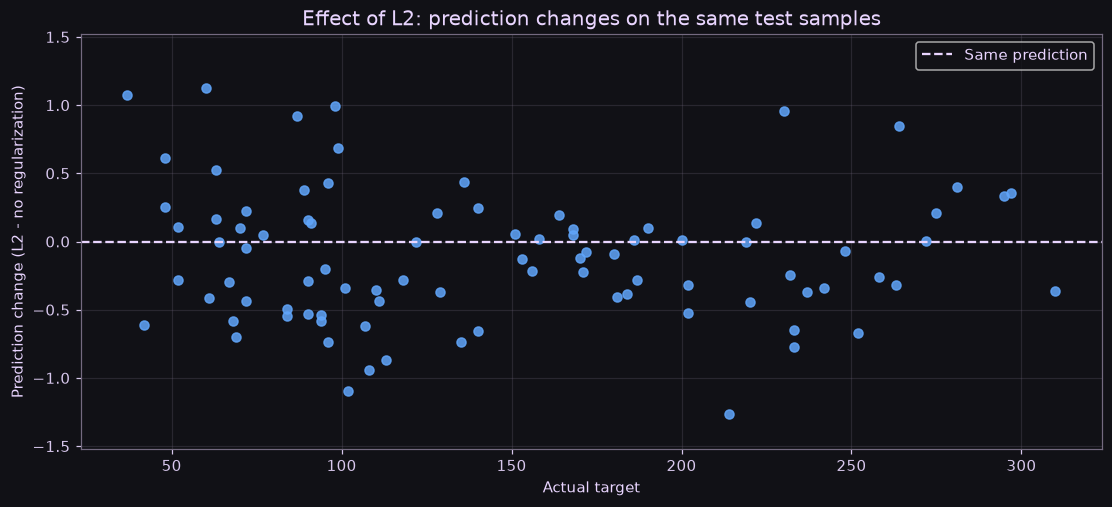

comparison,mean absolute prediction change,maximum absolute prediction change
L2 minus no regularization,0.3945,1.2653


In [7]:
prediction_changes = predictions["L2 regularization"] - predictions["No regularization"]
change_limit = max(float(np.abs(prediction_changes).max()) * 1.2, 0.01)
fig_change, ax_change = plt.subplots(figsize=(10, 4.5), layout="constrained")
ax_change.scatter(y_test.to_numpy(), prediction_changes, color=COLORS[2], alpha=0.85, s=35)
ax_change.axhline(0, color="#e9d5ff", linestyle="--", linewidth=1.5, label="Same prediction")
ax_change.set(
    title="Effect of L2: prediction changes on the same test samples",
    xlabel="Actual target",
    ylabel="Prediction change (L2 - no regularization)",
    ylim=(-change_limit, change_limit),
)
ax_change.grid(True)
ax_change.set_axisbelow(True)
ax_change.legend()
fig_change.savefig("diabetes_regularization_difference.png", dpi=160, facecolor=fig_change.get_facecolor())
plt.show()
colorize(pd.DataFrame({
    "comparison": ["L2 minus no regularization"],
    "mean absolute prediction change": [float(np.abs(prediction_changes).mean())],
    "maximum absolute prediction change": [float(np.abs(prediction_changes).max())],
}).round(4), index=False)

## <span style="color: #a855f7">Feature associations and interpretation</span>

<span style="color: #a855f7">для висновку про ознаки використовується кореляція Pearson з target лише на train, порядок - за абсолютною величиною, знак показує напрямок зв'язку, це не важливість ознак всередині MLP і не доказ причинності, bmi - індекс маси тіла, s5 - логарифм рівня тригліцеридів, взаємопов'язані ознаки ускладнюють окрему інтерпретацію</span>

In [8]:
correlations = X_train.corrwith(y_train)
correlations = correlations.reindex(correlations.abs().sort_values(ascending=False).index)
feature_associations = correlations.rename("train Pearson r").rename_axis("feature").to_frame()
colorize(feature_associations.round(4))
strongest_features = ", ".join(feature_associations.index[:2].tolist())
mae_effect = "lower" if mae_change < 0 else "higher" if mae_change > 0 else "unchanged"
r2_effect = "higher" if r2_change > 0 else "lower" if r2_change < 0 else "unchanged"
conclusions = [
    f"On this fixed test split, L2 gives {mae_effect} MAE and {r2_effect} R², the exact differences are shown in the comparison table",
    "A small L2 penalty does not guarantee better test metrics, especially after only 50 epochs, these two runs do not measure stability across random seeds",
    f"The strongest absolute train-only linear associations with the target are {strongest_features}, they are plausible contributors, not a causal or model-specific importance ranking",
    "Both networks use all ten features, the test set was not used to fit the scaler, train the models or select features",
]
display(HTML('<ul style="color: #a855f7">' + ''.join(f"<li>{escape(item)}</li>" for item in conclusions) + '</ul>'))

,train Pearson r
feature,
bmi,0.6048
s5,0.5522
bp,0.4448
s4,0.4251
s6,0.3904
s3,-0.3840
s1,0.1995
age,0.1965
s2,0.1549
